In [40]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [41]:
df = pd.read_csv("scholarship_prediction.csv")

In [42]:
df.head()

,student_id,age,gender,course,year,category,family_members,siblings,parent_employment,family_income,...,attendance,backlogs,hostel,rural_background,disability,first_generation,distance_from_college_km,annual_fee,previous_scholarship,scholarship_eligible
0,STU11502,20,Male,Diploma,4,General,5,2,Employed,247229,...,80.15,1,No,No,No,No,3.1,140620,No,0
1,STU12587,18,Male,B.Tech,4,General,6,5,Daily Wage,156146,...,57.45,0,Yes,No,No,No,17.2,85183,Yes,0
2,STU12654,18,Female,B.Com,3,OBC,7,6,Employed,127371,...,75.34,0,Yes,Yes,Yes,Yes,11.3,112641,No,1
3,STU11056,19,Male,B.Sc,3,EWS,5,4,Employed,269865,...,82.59,1,No,No,No,Yes,10.8,50667,No,0
4,STU10706,24,Male,B.A,2,General,6,5,Unemployed,110899,...,96.24,0,Yes,No,No,Yes,4.6,98766,No,1


In [4]:
df.columns

Index(['student_id', 'age', 'gender', 'course', 'year', 'category',
       'family_members', 'siblings', 'parent_employment', 'family_income',
       'previous_percentage', 'cgpa', 'attendance', 'backlogs', 'hostel',
       'rural_background', 'disability', 'first_generation',
       'distance_from_college_km', 'annual_fee', 'previous_scholarship',
       'scholarship_eligible'],
      dtype='str')

In [5]:
df.shape

(5000, 22)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   student_id                5000 non-null   str    
 1   age                       5000 non-null   int64  
 2   gender                    5000 non-null   str    
 3   course                    5000 non-null   str    
 4   year                      5000 non-null   int64  
 5   category                  5000 non-null   str    
 6   family_members            5000 non-null   int64  
 7   siblings                  5000 non-null   int64  
 8   parent_employment         5000 non-null   str    
 9   family_income             5000 non-null   int64  
 10  previous_percentage       5000 non-null   float64
 11  cgpa                      5000 non-null   float64
 12  attendance                5000 non-null   float64
 13  backlogs                  5000 non-null   int64  
 14  hostel             

In [7]:
df.describe()

,age,year,family_members,siblings,family_income,previous_percentage,cgpa,attendance,backlogs,distance_from_college_km,annual_fee,scholarship_eligible
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.01840,2.440000,4.794600,3.357400,226351.309200,71.646000,5.433758,78.084674,0.712600,9.383680,99768.432800,0.393400
std,1.63493,1.109345,1.474736,1.512786,122543.009823,12.081304,1.590624,10.740296,1.013018,6.500748,37320.722133,0.488553
min,17.00000,1.000000,2.000000,0.000000,30000.000000,35.000000,3.000000,45.000000,0.000000,0.500000,35092.000000,0.000000
25%,19.00000,1.000000,4.000000,2.000000,130738.750000,63.197500,4.180000,70.810000,0.000000,4.700000,66929.250000,0.000000
50%,20.00000,2.000000,5.000000,3.000000,210742.500000,71.635000,5.370000,78.145000,0.000000,8.000000,99898.500000,0.000000
75%,21.00000,3.000000,6.000000,4.000000,309752.000000,80.132500,6.552500,85.685000,1.000000,12.500000,131953.750000,1.000000
max,24.00000,4.000000,8.000000,6.000000,765267.000000,98.000000,10.000000,100.000000,4.000000,45.000000,164961.000000,1.000000


In [8]:
df.isnull().sum()

student_id                  0
age                         0
gender                      0
course                      0
year                        0
category                    0
family_members              0
siblings                    0
parent_employment           0
family_income               0
previous_percentage         0
cgpa                        0
attendance                  0
backlogs                    0
hostel                      0
rural_background            0
disability                  0
first_generation            0
distance_from_college_km    0
annual_fee                  0
previous_scholarship        0
scholarship_eligible        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["scholarship_eligible"].value_counts()

scholarship_eligible
0    3033
1    1967
Name: count, dtype: int64

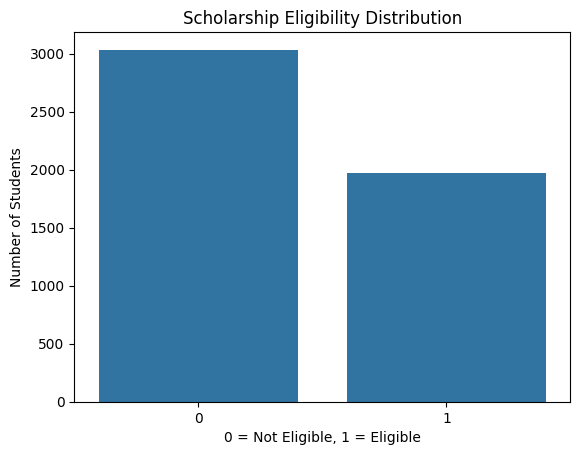

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(data=df, x="scholarship_eligible")
plt.title("Scholarship Eligibility Distribution")
plt.xlabel("0 = Not Eligible, 1 = Eligible")
plt.ylabel("Number of Students")
plt.show()

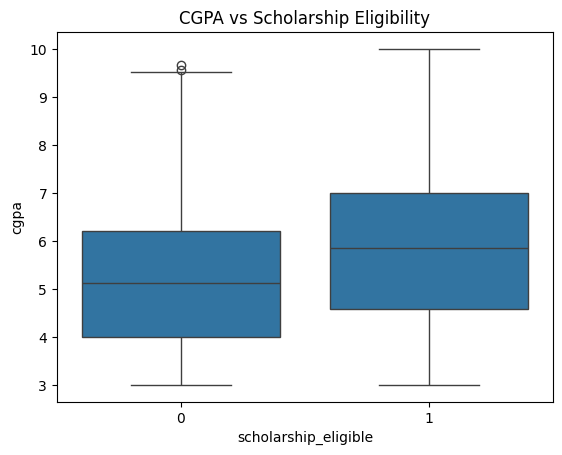

In [12]:
sns.boxplot(data=df, x="scholarship_eligible", y="cgpa")
plt.title("CGPA vs Scholarship Eligibility")
plt.show()

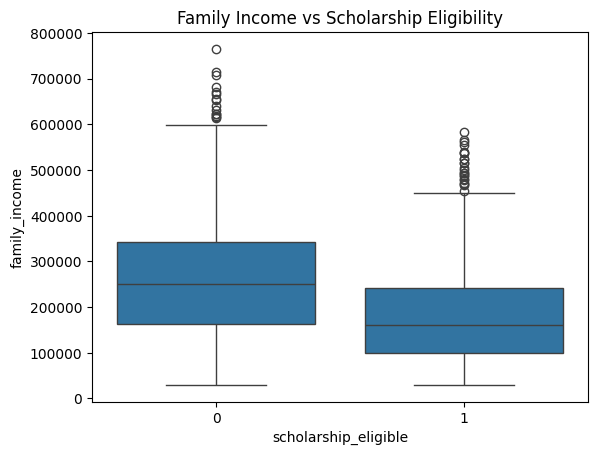

In [13]:
sns.boxplot(data=df, x="scholarship_eligible", y="family_income")
plt.title("Family Income vs Scholarship Eligibility")
plt.show()

In [14]:
df.select_dtypes(include="object").columns.tolist()

['student_id',
 'gender',
 'course',
 'category',
 'parent_employment',
 'hostel',
 'rural_background',
 'disability',
 'first_generation',
 'previous_scholarship']

In [15]:
X = df.drop(columns=["scholarship_eligible", "student_id"])
y = df["scholarship_eligible"]
print(X.shape)
print(y.shape)

(5000, 20)
(5000,)


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [44]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4000, 20)
(1000, 20)
(4000,)
(1000,)


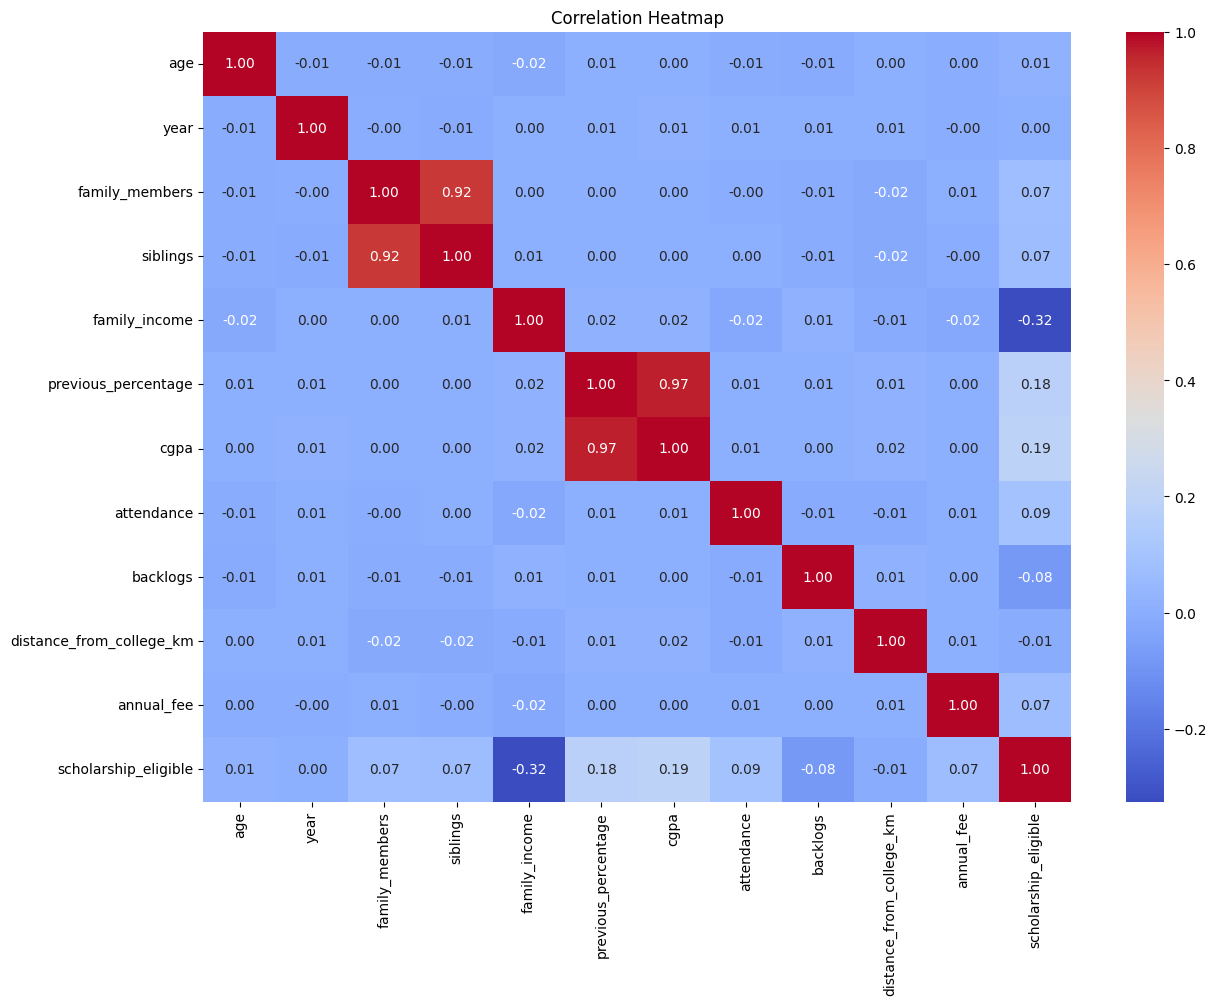

In [45]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [46]:
corr["scholarship_eligible"].sort_values(ascending=False)

scholarship_eligible        1.000000
cgpa                        0.190017
previous_percentage         0.180887
attendance                  0.093336
family_members              0.071361
annual_fee                  0.066411
siblings                    0.065769
age                         0.014978
year                        0.004990
distance_from_college_km   -0.009089
backlogs                   -0.079498
family_income              -0.324939
Name: scholarship_eligible, dtype: float64

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Encode categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])


model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [48]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.692

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.82      0.76       607
           1       0.64      0.49      0.56       393

    accuracy                           0.69      1000
   macro avg       0.68      0.66      0.66      1000
weighted avg       0.69      0.69      0.68      1000



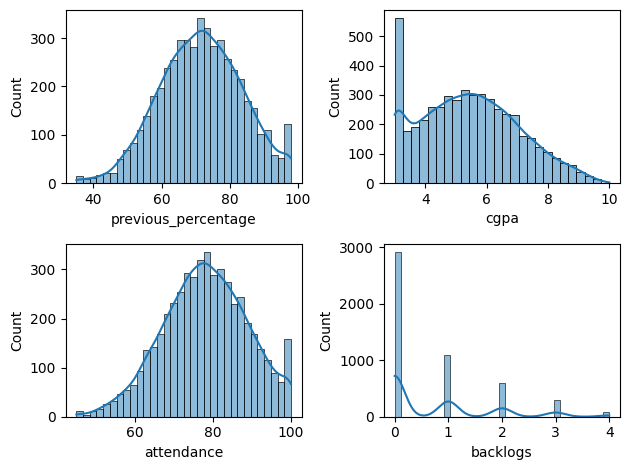

In [23]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde = True)

plotting('previous_percentage',1)    
plotting('cgpa',2)  
plotting('attendance',3)  
plotting('backlogs',4)  

plt.tight_layout()

In [24]:
# data preprocessing and cleaning

In [25]:
df_encode = pd.get_dummies(df,drop_first=True)

In [26]:
df_encode

,age,year,family_members,siblings,family_income,previous_percentage,cgpa,attendance,backlogs,distance_from_college_km,...,category_ST,parent_employment_Employed,parent_employment_Retired,parent_employment_Self-Employed,parent_employment_Unemployed,hostel_Yes,rural_background_Yes,disability_Yes,first_generation_Yes,previous_scholarship_Yes
0,20,4,5,2,247229,71.39,5.38,80.15,1,3.1,...,False,True,False,False,False,False,False,False,False,False
1,18,4,6,5,156146,74.02,4.94,57.45,0,17.2,...,False,False,False,False,False,True,False,False,False,True
2,18,3,7,6,127371,64.31,3.83,75.34,0,11.3,...,False,True,False,False,False,True,True,True,True,False
3,19,3,5,4,269865,71.49,5.23,82.59,1,10.8,...,False,True,False,False,False,False,False,False,True,False
4,24,2,6,5,110899,63.85,4.23,96.24,0,4.6,...,False,False,False,False,True,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,19,3,4,3,122443,53.76,3.00,75.99,2,12.2,...,False,False,False,False,False,False,False,False,True,True
4996,19,3,6,5,107731,68.35,4.47,79.94,0,5.6,...,True,False,False,False,False,True,False,False,True,False
4997,19,1,6,3,201022,71.82,4.99,78.92,2,8.4,...,False,True,False,False,False,False,True,False,True,False
4998,19,2,4,3,112794,70.44,4.67,77.12,0,5.2,...,False,False,False,True,False,False,False,False,True,False


In [27]:
df_encode = df_encode.astype(int)

In [28]:
df_encode

,age,year,family_members,siblings,family_income,previous_percentage,cgpa,attendance,backlogs,distance_from_college_km,...,category_ST,parent_employment_Employed,parent_employment_Retired,parent_employment_Self-Employed,parent_employment_Unemployed,hostel_Yes,rural_background_Yes,disability_Yes,first_generation_Yes,previous_scholarship_Yes
0,20,4,5,2,247229,71,5,80,1,3,...,0,1,0,0,0,0,0,0,0,0
1,18,4,6,5,156146,74,4,57,0,17,...,0,0,0,0,0,1,0,0,0,1
2,18,3,7,6,127371,64,3,75,0,11,...,0,1,0,0,0,1,1,1,1,0
3,19,3,5,4,269865,71,5,82,1,10,...,0,1,0,0,0,0,0,0,1,0
4,24,2,6,5,110899,63,4,96,0,4,...,0,0,0,0,1,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,19,3,4,3,122443,53,3,75,2,12,...,0,0,0,0,0,0,0,0,1,1
4996,19,3,6,5,107731,68,4,79,0,5,...,1,0,0,0,0,1,0,0,1,0
4997,19,1,6,3,201022,71,4,78,2,8,...,0,1,0,0,0,0,1,0,1,0
4998,19,2,4,3,112794,70,4,77,0,5,...,0,0,0,1,0,0,0,0,1,0


In [29]:
#data cleaning and preprocessing

df_cleaned = df.copy()

In [30]:
df_cleaned.head()

,student_id,age,gender,course,year,category,family_members,siblings,parent_employment,family_income,...,attendance,backlogs,hostel,rural_background,disability,first_generation,distance_from_college_km,annual_fee,previous_scholarship,scholarship_eligible
0,STU11502,20,Male,Diploma,4,General,5,2,Employed,247229,...,80.15,1,No,No,No,No,3.1,140620,No,0
1,STU12587,18,Male,B.Tech,4,General,6,5,Daily Wage,156146,...,57.45,0,Yes,No,No,No,17.2,85183,Yes,0
2,STU12654,18,Female,B.Com,3,OBC,7,6,Employed,127371,...,75.34,0,Yes,Yes,Yes,Yes,11.3,112641,No,1
3,STU11056,19,Male,B.Sc,3,EWS,5,4,Employed,269865,...,82.59,1,No,No,No,Yes,10.8,50667,No,0
4,STU10706,24,Male,B.A,2,General,6,5,Unemployed,110899,...,96.24,0,Yes,No,No,Yes,4.6,98766,No,1


In [49]:
from scipy.stats import pearsonr

selected_features = [
    'age',
    'year',
    'family_members',
    'siblings',
    'family_income',
    'previous_percentage',
    'cgpa',
    'attendance',
    'backlogs',
    'distance_from_college_km',
    'annual_fee'
]

correlations = {
    feature: pearsonr(
        df[feature],
        df['scholarship_eligible']
    )[0]
    for feature in selected_features
}

correlation_df = pd.DataFrame(
    list(correlations.items()),
    columns=['Feature', 'Pearson Correlation']
)

correlation_df = correlation_df.sort_values(
    by='Pearson Correlation',
    ascending=False
)

print(correlation_df)

                     Feature  Pearson Correlation
6                       cgpa             0.190017
5        previous_percentage             0.180887
7                 attendance             0.093336
2             family_members             0.071361
10                annual_fee             0.066411
3                   siblings             0.065769
0                        age             0.014978
1                       year             0.004990
9   distance_from_college_km            -0.009089
8                   backlogs            -0.079498
4              family_income            -0.324939


In [51]:
importance = pd.Series(model.named_steps["classifier"].feature_importances_, index=model.named_steps["preprocessor"].get_feature_names_out()).sort_values(ascending=False)
print(importance.head(15))

num__family_income                   0.140795
num__previous_percentage             0.089868
num__cgpa                            0.086998
num__attendance                      0.080868
num__annual_fee                      0.075811
num__distance_from_college_km        0.073296
num__age                             0.039659
num__family_members                  0.035377
num__siblings                        0.034991
num__year                            0.028521
num__backlogs                        0.027782
cat__category_General                0.016429
cat__parent_employment_Unemployed    0.014245
cat__parent_employment_Employed      0.012708
cat__first_generation_No             0.012228
dtype: float64
